## Pegasus Evaluation: Evidence per Service

Sections B.2 and B.2b of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b, deactivated), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
from pegasus.figures import math_label
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics/evaluation_cache/b1_real+b1+b1u-max3_884f34446e6214f4.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 120 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.2 Varying Evidence per Service

**Question.** A chain is only as well known as its least known service. If the training runs of a chain are collected
one service at a time, which service should get them, and how many runs does the bound need to become valid and
tight?

- **Synthetic:** the chain of B.1 ($s_1 \to s_2 \to s_3$), with up to 200 training configurations per service.
- **Real:** the chain denoiser → object detector → face detector → compressor (`EVIDENCE_CHAIN` in
  `pegasus/evaluation_setup.py`, `b1-vision-3-single` with its runs in `b1-unthrottled/` with at most three workers per
  service, as in B.1). Of all chains of the campaign, its services are the least evenly known: with few training runs,
  the models of the object detector and the face detector are far more uncertain than those of the other two services,
  so the order in which the services get their runs matters. Which service the rule below picks first follows from the
  models, not from this choice of chain (the conclusion names it).
- **Baselines:** as in B.1 without DNN Sum (see Methods in B.1), each with the same training data as the proposed
  method. Of the proposed method, only Pegasus Node is evaluated: Pegasus SNC is evaluated in B.1 and B.3 only.

**Training data (real data).** Unlike B.1, every service is trained on its benchmark *and* on its runs in the other
chains of `b1/` (`BENCHMARK_AND_CHAINS` in `pegasus/real_data.py`); the evaluated chain and its twin in
`b1-unthrottled/` are left out, so the chain stays an unseen composition. The reason: a benchmark measures ten
configurations of its service, each at five utilizations, so beyond a few dozen runs it only adds repetitions of the
same configurations. The other chains drew the configuration of every run at random and add configurations that the
benchmark lacks. They run every service with one worker, as the benchmark does. A training run is one run with its
mean and its spread, as in B.1; with synthetic data, one training configuration with one execution time.

**Setting.** B.2 does not use the chain of B.1 that the first code cell loads and prints; it takes from that base case
only the number of training runs per service of B.1, for the calibration share of Conformal (below). For every seed,
the training runs of every service come in one random order (`evidence_data` in `pegasus/evaluation_setup.py`), and
$n$ runs of a service are the first $n$ of them, so that more runs only add to the fewer ones. Every service starts
with the first number of `evidence_levels` (in the code cell below) and moves up through these numbers, the last step
being all its runs (`service_levels` in `pegasus/evidence.py`). One *step* moves one service to its next number; after
every step the models are fitted anew, and every method is computed on the held-out runs, which are those of B.1 for
this chain and the same under every seed. A *schedule* decides which service moves (`pegasus/evidence.py`):
- *All services together:* the services in turn, in the order of the chain, so that all of them grow alike.
- *Most uncertain first:* the service whose uncertainty costs the bound of Pegasus Node the most. Let $\bar m_k(x)$ be
  the pessimistic mean execution time of service $k$ at the held-out configuration $x$ (s, see Methods in B.1),
  $m_k(x)$ its predicted mean (s), and $d_k$ the node bound of service $k$ at the violation probability
  $\varepsilon / |S|$ (s, as in Pegasus Node), computed from a mean and the variance per item. The *cost of the
  uncertainty* of service $k$ is the median over the held-out configurations of $d_k(\bar m_k(x)) - d_k(m_k(x))$: how
  much its node bound would shrink if its mean were known (infinite where only the pessimistic mean overloads the
  service). It uses the models, the held-out configurations and their arrival rates, not a single measured latency, so
  it can be computed before the chain ever runs: a rule that a user can follow (`uncertainty_cost`).
- *Least uncertain first:* the service with the smallest cost, the control.

Conformal sets aside the same share of the runs of the service with the fewest runs for calibration as in B.1, and at
least 19, the fewest that give it a finite bound; it is left out where fewer than 5 runs would remain to train its
model. The Oracle uses no training data.

**Complexity (against the amount of training data).** Training time and evaluation time are defined in B.1
(Metrics). With $n$ training runs per service, training a GP costs on the order of $n^3$ operations per step of its
hyperparameter search, because every step factorizes an $n \times n$ matrix; the training time of every method is
therefore expected to grow with $n$, and faster than linearly for large $n$. A prediction of a trained GP at one
held-out configuration costs on the order of $n$ operations for the mean and $n^2$ for the variance. The evaluation
time contains these predictions and the computation of the bound from them, which does not depend on $n$; the
evaluation time is therefore expected to stay far below the training time. The complexity against the depth of the
application is analyzed in B.3.

**Figures.** The horizontal axis of every figure is the total number of training runs of the chain, all services
together (logarithmic). Every line is the median over the seeds, and the band around it reaches from the smallest to
the largest seed; the legend of every figure sits inside it where it hides the fewest points.
- *Schedules* (`b2_evidence_<data source>_schedules_tightness`): the tightness of Pegasus Node under every schedule, for
  every seed the median over the held-out configurations. Under the two schedules that look at the uncertainty, the
  services move in a different order under every seed; the horizontal position of a step is then the median over the
  seeds of the total number of runs. The horizontal line at 1× is the measured quantile; in the red area below it
  ("underestimated: SLO violated") the bound lies under the measured quantile. A filled marker means that the bound
  holds after that step (it reaches the confidence level under every seed, as defined in B.1), a hollow marker that it
  does not; a step has no point where the bound is infinite at half of the held-out configurations or more under half
  of the seeds or more. Look at how many runs each schedule needs before its markers are filled, and where its line
  is lowest.
- *Runs per service* (`_schedules_runs`): the training runs of every service under *most uncertain first*, the median
  over the seeds: which service the rule feeds first.
- *Methods* (`b2_evidence_<data source>_tightness`, `_training`, `_evaluation`): every method under *all services
  together*, as tightness (read as the first figure), training time (s, logarithmic, one line per set of trained models;
  the legend names the methods that use these models) and evaluation time (s, logarithmic, one line per method).

The figures are saved in `figures/tsc/` as `.pdf` and `.jpg`.

In [ ]:
# B.2: the chain of B.2 while the training runs of its services grow one service at a time, under every schedule (pegasus/evidence.py)
from pegasus.evidence import (ALL_TOGETHER, COLORS as SCHEDULE_COLORS, MOST_UNCERTAIN, SCHEDULES, STYLES as SCHEDULE_STYLES, incremental_training,
                              schedule_figure)
from pegasus.figures import METHOD_STYLES

METHOD_COLORS.update(SCHEDULE_COLORS)   # sweep_line draws a line by its name
METHOD_STYLES.update(SCHEDULE_STYLES)
evidence_levels = [3, 10, 50]                 # training runs (configurations) per service at which a service stops; then all of them
calibration_share = n_calibration / n_train   # share of its runs that Conformal sets aside for calibration, as in B.1


def compute():
    evidence = {}         # (schedule, seed) -> per step: (runs per service, name -> (group, latency per held-out configuration),
                          #                               name -> (training time, evaluation time) in s, the service that moves up next)
    evidence_truth = {}   # seed -> (measured quantile, lower edge of its confidence interval) per held-out configuration
    with warnings.catch_warnings():
        # with few training runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            data = evidence_data(s)
            assert_unseen(data)
            evidence_truth[s] = (data.measured, data.measured_low)
            for schedule in SCHEDULES:
                evidence[(schedule, s)] = incremental_training(data, schedule, evidence_levels, alpha, confidence, calibration_share,
                                                               model_seed=seed + s, leave_out=only_base_case + (PROPOSED_SNC,))
    return dict(evidence=evidence, evidence_truth=evidence_truth, evidence_path=data.path)


globals().update(cached("b2_evidence", data_source, compute, inputs=dict(levels=evidence_levels, calibration_share=calibration_share)))
n_steps = len(evidence[(ALL_TOGETHER, seeds[0])])
print(f"{len(SCHEDULES)} schedules of {n_steps} training states each evaluated for {len(seeds)} seeds on {' -> '.join(evidence_path)}, "
      f"{len(evidence_truth[seeds[0]][0])} held-out configurations.")

B.2 evidence per service, real data: denoiser → detector → faces → compressor, Pegasus Node under every schedule, 107 held-out configurations, 3 seeds
save_figure: b2_evidence_real_schedules_tightness reaches beyond the figure by {'right': np.float64(0.02)} inches


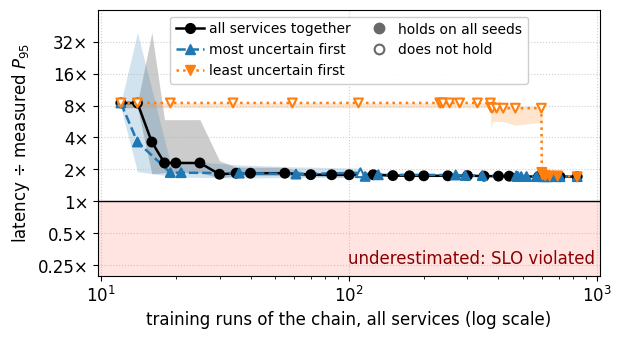

save_figure: b2_evidence_real_schedules_runs reaches beyond the figure by {'right': np.float64(0.02), 'bottom': np.float64(0.05), 'top': np.float64(0.51)} inches


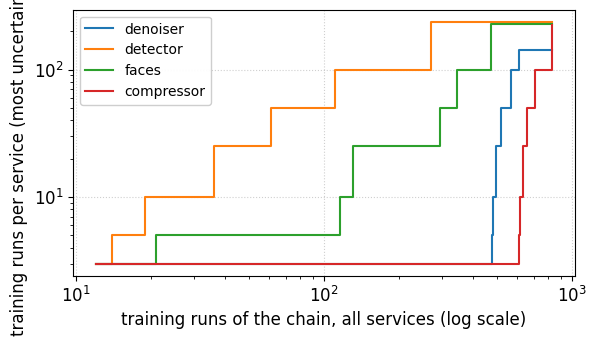

B.2 evidence per service, real data: denoiser → detector → faces → compressor, all services together, 107 held-out configurations, 3 seeds
legend_inside: the legend hides 3 points or bands at its best location (upper center)


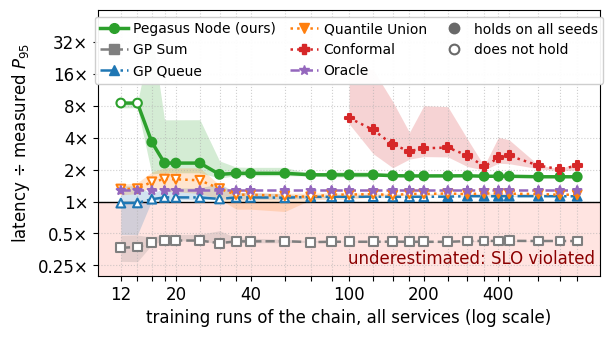

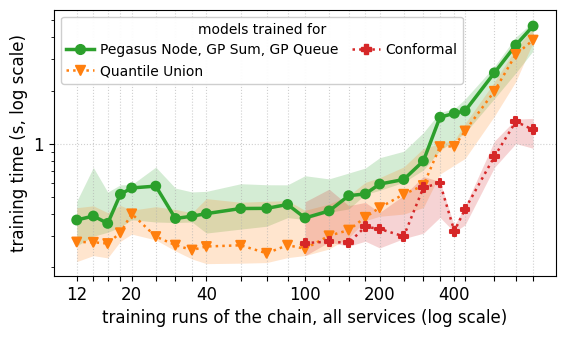

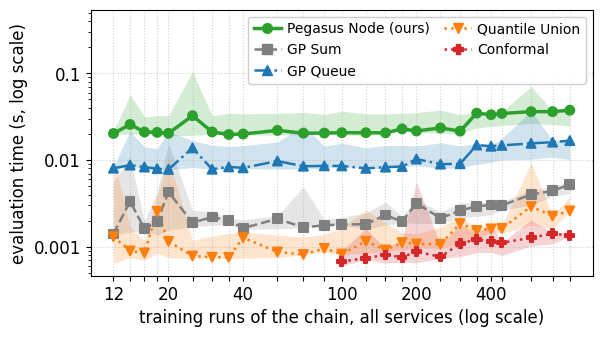

In [3]:
# B.2: coverage and tightness per training state; the ground truth is the same at every state
training_unit = "training runs" if data_source == "real" else "training configurations"
steps = list(range(n_steps))
per_step = lambda schedule: {(k, s): evidence[(schedule, s)][k][1] for k in steps for s in seeds}   # (step, seed) -> name -> (group, latency)
step_truth = {(k, s): evidence_truth[s] for k in steps for s in seeds}
runs_of = lambda schedule: np.array([[[evidence[(schedule, s)][k][0][node] for node in evidence_path] for s in seeds] for k in steps])   # (steps, seeds, services)
# total runs of the chain at every step, the median over the seeds (the same under every seed for ALL_TOGETHER)
evidence_totals = {schedule: np.median(runs_of(schedule).sum(axis=2), axis=1) for schedule in SCHEDULES}
schedule_statistics = {schedule: sweep_statistics(per_step(schedule), step_truth, steps, seeds, confidence)[PROPOSED] for schedule in SCHEDULES}
schedule_figure(evidence_totals, schedule_statistics, runs_of(MOST_UNCERTAIN), evidence_path,
                f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, Pegasus Node under every schedule, "
                f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label, name=f"b2_evidence_{data_source}_schedules")

# every method under ALL_TOGETHER, whose totals are the same under every seed; a tick only where all services have the same number of runs
together = {(evidence_totals[ALL_TOGETHER][k], s): evidence[(ALL_TOGETHER, s)][k][1] for k in steps for s in seeds}
together_seconds = {(evidence_totals[ALL_TOGETHER][k], s): evidence[(ALL_TOGETHER, s)][k][2] for k in steps for s in seeds}
together_truth = {(evidence_totals[ALL_TOGETHER][k], s): evidence_truth[s] for k in steps for s in seeds}
together_totals = list(evidence_totals[ALL_TOGETHER])
evidence_statistics = sweep_statistics(together, together_truth, together_totals, seeds, confidence)   # name -> coverage, tightness, holds, computed
evidence_times = sweep_seconds(together_seconds, together_totals, seeds)                                # name -> training, evaluation
equal = runs_of(ALL_TOGETHER)[:, 0, :]
tightness_and_time_figure(together_totals, evidence_statistics, evidence_times, f"{training_unit} of the chain, all services (log scale)",
                          f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, all services together, "
                          f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label,
                          tick_labels=[f"{total:g}" if (row == row[0]).all() else "" for total, row in zip(together_totals, equal)],
                          name=f"b2_evidence_{data_source}")

In [4]:
total_label = lambda total: f"{total:g} {training_unit}"
# median over the seeds of the tightness of Pegasus Node at every step; a seed without a finite tightness counts as infinitely loose
typical = lambda schedule: np.median(np.nan_to_num(schedule_statistics[schedule]["tightness"], nan=np.inf), axis=1)
usable = lambda schedule: schedule_statistics[schedule]["holds"] & np.isfinite(typical(schedule))   # per step: holds with a finite bound


def schedule_text(schedule):
    ok, totals, tight = usable(schedule), evidence_totals[schedule], typical(schedule)
    if not ok.any():
        return f"*{schedule}*: no valid finite bound at any step"
    first = int(np.argmax(ok))
    best = int(np.argmin(np.where(ok, tight, np.inf)))
    stays = "and at every later step" if ok[first:].all() else "but not at every later step"
    return (f"*{schedule}*: valid and finite from {total_label(totals[first])} on ({tight[first]:.2f}×) {stays}; tightest "
            f"{tight[best]:.2f}× at {total_label(totals[best])}; {tight[-1]:.2f}× with all runs")


first_moves = [evidence[(MOST_UNCERTAIN, s)][0][3] for s in seeds]   # the service that the rule moves up first, under every seed
display(Markdown(
    f"**What this shows** ({data_source} data, {' → '.join(evidence_path)}, ε = {alpha:g}, {len(seeds)} seeds; training runs counted "
    f"for the whole chain).\n"
    "- **Pegasus Node under every schedule** (median over the seeds): " + "; ".join(schedule_text(schedule) for schedule in SCHEDULES) + ".\n"
    f"- **Which service the rule feeds first.** Under *{MOST_UNCERTAIN}* the first service to get more runs is "
    + ", ".join(f"{service} (seed {s})" for service, s in zip(first_moves, seeds)) + ".\n\n"
    f"*Every method under {ALL_TOGETHER}.*\n"
    + sweep_conclusion(together_totals, evidence_statistics, sweep_competitors, total_label) + "\n"
    + time_conclusion(together_totals, evidence_times, sweep_competitors, total_label)
))

**What this shows** (real data, denoiser → detector → faces → compressor, ε = 0.05, 3 seeds; training runs counted for the whole chain).
- **Pegasus Node under every schedule** (median over the seeds): *all services together*: valid and finite from 16 training runs on (3.62×) and at every later step; tightest 1.71× at 708 training runs; 1.71× with all runs; *most uncertain first*: valid and finite from 14 training runs on (3.63×) but not at every later step; tightest 1.71× at 658 training runs; 1.71× with all runs; *least uncertain first*: valid and finite from 598 training runs on (1.88×) and at every later step; tightest 1.71× at 831 training runs; 1.71× with all runs.
- **Which service the rule feeds first.** Under *most uncertain first* the first service to get more runs is detector (seed 0), detector (seed 1), detector (seed 2).

*Every method under all services together.*
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Conformal. Methods that do not hold, and where: Pegasus Node (ours) at 12 training runs, 14 training runs; GP Sum at every setting; GP Queue at 12 training runs, 14 training runs, 16 training runs, 18 training runs, 20 training runs, 25 training runs, 30 training runs, 35 training runs, 40 training runs, 55 training runs, 70 training runs, 85 training runs, 100 training runs, 125 training runs, 150 training runs, 175 training runs, 200 training runs; Quantile Union at 12 training runs, 14 training runs, 16 training runs, 18 training runs, 20 training runs, 25 training runs, 30 training runs, 35 training runs, 40 training runs, 55 training runs, 70 training runs, 85 training runs, 100 training runs, 125 training runs, 150 training runs, 175 training runs, 200 training runs, 250 training runs. Conformal is not computed at 12 training runs, 14 training runs, 16 training runs, 18 training runs, 20 training runs, 25 training runs, 30 training runs, 35 training runs, 40 training runs, 55 training runs, 70 training runs, 85 training runs.
- **Tightness among the methods that hold** (median over the seeds): Conformal from 6.12× at 100 training runs to 2.18× at 831 training runs.
- **Training time** (median over the seeds; methods that share their models are named together): Pegasus Node (ours), GP Sum, GP Queue 0.37 s at 12 training runs and 4.6 s at 831 training runs; Quantile Union 0.28 s at 12 training runs and 3.9 s at 831 training runs; Conformal 0.27 s at 100 training runs and 1.2 s at 831 training runs.
- **Evaluation time** (median over the seeds): Pegasus Node (ours) 0.02 s at 12 training runs and 0.038 s at 831 training runs; GP Sum 0.0014 s at 12 training runs and 0.0052 s at 831 training runs; GP Queue 0.008 s at 12 training runs and 0.017 s at 831 training runs; Quantile Union 0.0013 s at 12 training runs and 0.0026 s at 831 training runs; Conformal 0.00068 s at 100 training runs and 0.0014 s at 831 training runs.

#### B.2b Choosing the Next Configuration

**Deactivated** for both data sources (`run_b2b` in the next code cell): the code cells of B.2b compute and show
nothing. The description below is kept for when it is activated again.

**Question.** B.2 draws the training configurations at random. Does the bound become valid and tight with fewer
benchmarks if the next configuration is chosen with what the models already know?

- **Synthetic:** when activated, run first, whatever `data_source` is set to: only the synthetic system can be benchmarked at any
  configuration.
- **Real:** skipped. It selects among the runs of the first campaign (`real_exploration_results` in
  `pegasus/exploration.py`), which this notebook no longer evaluates; the description below is kept for a later port
  to the second campaign.
- **Method evaluated:** Pegasus Node. The baselines that need a service monitored under load are left out, because
  they would need a strategy of their own for their latency models.

**Setting (synthetic data).** The chain, the held-out configurations and the ground truth of the synthetic B.1, for every seed. A
*benchmark* of a configuration measures one execution time of every service at that configuration (all services of a
synthetic chain share one configuration). A *sampling strategy* decides which configuration is benchmarked next. Every
strategy benchmarks `explore_sizes[-1]` configurations one after the other; after $n$ benchmarks, the models are fitted
to the first $n$ configurations as in B.2, and the bound is computed at the held-out configurations.

**Strategies (`pegasus/exploration.py`).** Two do not look at the models:
- *Random:* every configuration is drawn uniformly at random, as in B.2.
- *Sobol sequence:* the first points of a scrambled Sobol sequence, which fills the space more evenly than random
  draws.

Four are adaptive. They start from `n_initial` random configurations, the same for all four. Before every further
benchmark, one GP per service is fitted to the configurations benchmarked so far, an *acquisition function* gives every
candidate configuration a score, and the candidate with the largest score is benchmarked. The candidates are a fixed
set of random configurations. With $m_k(x)$ the predicted mean execution time (s) of service $k$ at the configuration
$x$ and $\sigma_k^2(x)$ the variance of that mean (the GP's uncertainty about the mean, without the scatter of single
items):
- *Maximum variance* (uncertainty sampling): the score is $\sum_k \sigma_k^2(x)$. It benchmarks where the models know
  least, which is often at the edge of the space.
- *Variance reduction:* the score is how much a benchmark at $x$ would reduce the variance of the mean at a set of
  reference configurations spread over the space, summed over the services. Unlike maximum variance, it counts what a
  benchmark tells about the rest of the space.
- *Upper confidence bound:* the score is $\sum_k m_k(x) + 2\sqrt{\sum_k \sigma_k^2(x)}$, the predicted total
  execution time of the chain plus two standard deviations. It benchmarks configurations that are slow or uncertain,
  where the queues are longest.
- *Expected improvement:* the score is the expected amount by which the total execution time at $x$ falls below the
  smallest total measured so far. It is the acquisition function of Bayesian optimization for finding the fastest
  configuration, and is included to show what a strategy does that searches for an optimum instead of learning the
  whole space.

**Figures.** Two separate figures, each with the number of benchmarked configurations on the horizontal axis
(logarithmic) and one line per strategy. Every line is the median over the seeds, and the band around it reaches from the smallest to the largest seed; the
legend of every figure sits inside it where it hides the fewest points.
- *Tightness* of Pegasus Node, for every seed the median over its held-out configurations. A filled marker means that
  the bound holds with the configurations of that strategy (it reaches the confidence level under every seed, as
  defined in B.1), a hollow marker that it does not. In the red area below 1× the bound is under the measured quantile.
- *Error of the predicted mean execution time* in percent: the median over the held-out configurations and the
  services of |predicted mean ÷ true mean − 1|.

Look first at which strategies have filled markers with few benchmarks, then at whether an adaptive strategy lies below
the random one. The figures are also saved as `figures/tsc/b2b_sampling_strategies_synthetic_tightness.pdf` and
`_error.pdf`, each with a `.jpg`.

In [5]:
run_b2b = False   # B.2b is deactivated for both data sources; True runs its synthetic part again
if not run_b2b:
    print("B.2b skipped: deactivated for both data sources")
else:
    # B.2b: the training configurations chosen one by one under different sampling strategies. This cell imports what it needs
    # itself and always uses the synthetic system, so nothing above has to be run again.
    from pegasus.exploration import COLORS as STRATEGY_COLORS, RANDOM, STRATEGIES, STYLES as STRATEGY_STYLES, exploration_figure, exploration_results, explore
    from pegasus.figures import METHOD_STYLES

    METHOD_COLORS.update(STRATEGY_COLORS)   # sweep_line draws a line by its name
    METHOD_STYLES.update(STRATEGY_STYLES)
    explore_sizes = [10, 15, 25, 50]        # numbers of benchmarked configurations at which the bound is evaluated
    n_initial = 5                           # random configurations that an adaptive strategy starts from


    def compute():
        synthetic_bases = bases if data_source == "synthetic" else {
            s: load_chain_data("synthetic", path=synthetic_chain(3), level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s) for s in seeds}
        explore_bounds, explore_truth = {}, {}                                                        # (size, seed) -> strategy -> ("proposed", latency per held-out configuration) / truth
        explore_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in STRATEGIES}   # relative error of the predicted mean
        with warnings.catch_warnings():
            # with few configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for j, s in enumerate(seeds):
                data = synthetic_bases[s]
                for strategy in STRATEGIES:
                    x, y = explore(strategy, data.path, s, explore_sizes[-1], n_initial, seed=[seed, s, 200])
                    results = exploration_results(data, x, y, explore_sizes, s, alpha, confidence, model_seed=seed + s)
                    for i, size in enumerate(explore_sizes):
                        explore_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                        explore_truth[(size, s)] = (data.measured, data.measured_low)
                        explore_error[strategy][i, j] = results[size][1]
        return dict(synthetic_bases=synthetic_bases, explore_bounds=explore_bounds, explore_truth=explore_truth, explore_error=explore_error)


    globals().update(cached("b2b_strategies", data_source, compute, inputs=dict(explore_sizes=explore_sizes, n_initial=n_initial, strategies=list(STRATEGIES))))
    print(f"{len(STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

B.2b skipped: deactivated for both data sources


In [6]:
if not run_b2b:
    print("B.2b skipped: deactivated for both data sources")
else:
    explore_statistics = sweep_statistics(explore_bounds, explore_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
    exploration_figure(explore_sizes, explore_statistics, explore_error,
                       f"B.2b sampling strategies, synthetic data: {' → '.join(synthetic_bases[seeds[0]].path)}, Pegasus Node, {len(seeds)} seeds", p_label,
                       name="b2b_sampling_strategies_synthetic")

B.2b skipped: deactivated for both data sources


In [7]:
if not run_b2b:
    print("B.2b skipped: deactivated for both data sources")
else:
    explore_label = lambda size: f"{size} benchmarks"
    error_at = lambda strategy, size: np.median(explore_error[strategy][explore_sizes.index(size)])   # median over the seeds
    lowest_coverage = lambda strategy, size: explore_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
    display(Markdown(
        f"**What this shows** (synthetic data, Pegasus Node, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(explore_sizes, explore_statistics, list(STRATEGIES), explore_label)
        + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
        + " and ".join(explore_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {error_at(strategy, explore_sizes[0]):.1%} and {error_at(strategy, explore_sizes[-1]):.1%}" for strategy in STRATEGIES)
        + ".\n- **Lowest coverage over the seeds** with " + explore_label(explore_sizes[0]) + ": "
        + ", ".join(f"{strategy} {lowest_coverage(strategy, explore_sizes[0]):.2f}" for strategy in STRATEGIES)
        + f". The level to reach is {confidence:.2f}."
    ))

B.2b skipped: deactivated for both data sources


**Setting (real data; skipped, see above).** The chain, the held-out runs and the ground truth of the real B.1 of the first
campaign (qr → cv → face), for every seed. What differs from the
synthetic part:
- A *benchmark* is one measured run of one service, with the mean and the spread of its processing times (see Training
  data in B.1). A strategy *selects* it from the runs that may train the service: its runs alone and in pipelines of
  another topology, several hundred per service. It sees the configurations of all these runs, and the processing
  times only of the runs it has selected.
- Every service selects its own runs, because the real services have their own knobs; after $n$ selections per
  service, the models are fitted as in B.2.
- The adaptive strategies use the mean model of the real data, a GP on the logarithm of the run means. Their scores
  are therefore relative: the upper confidence bound prefers runs that are slow or uncertain by a factor, and the
  expected improvement is an improvement of the logarithm of the mean processing time.
- A fixed set of runs has no Sobol sequence. Its counterpart is *farthest point*: after the initial random runs, always
  the run whose configuration is farthest from the configurations selected so far (in standardized knobs). Like the
  Sobol sequence, it spreads the runs over the space without looking at a model.

The figure is the one of the synthetic part, with the number of selected runs per service on the horizontal axis. A
strategy has no point where, for half of the seeds or more, the bound is infinite at half of the held-out runs or
more.

In [8]:
if not run_b2b:
    print("B.2b real skipped: deactivated for both data sources")
elif "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    # B.2b, real data: every service selects its training runs one by one among its measured runs (real_exploration_results in
    # pegasus/exploration.py). This cell imports what it needs itself, so nothing above has to be run again.
    from pegasus.exploration import POOL_STRATEGIES, real_exploration_results

    explore_experiment = "04e-chain-qr-cv-face"   # the real chain of B.1
    real_bases = bases if data_source == "real" else {
        s: load_chain_data("real", experiment=explore_experiment, utilization=0.5, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s]) for s in seeds}
    pool_bounds, pool_truth = {}, {}                                                                    # (size, seed) -> strategy -> ("proposed", latency per held-out run) / truth
    pool_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in POOL_STRATEGIES}   # relative error of the predicted mean
    with warnings.catch_warnings():
        # with few runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            for strategy in POOL_STRATEGIES:
                results = real_exploration_results(explore_experiment, real_bases[s], strategy, explore_sizes, n_initial, seed=[seed, s, 300], alpha=alpha,
                                                   confidence=confidence, model_seed=seed + s)
                for i, size in enumerate(explore_sizes):
                    pool_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                    pool_truth[(size, s)] = (real_bases[s].measured, real_bases[s].measured_low)
                    pool_error[strategy][i, j] = results[size][1]
    print(f"{len(POOL_STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

B.2b real skipped: deactivated for both data sources


In [9]:
if not run_b2b:
    print("B.2b real skipped: deactivated for both data sources")
elif "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_statistics = sweep_statistics(pool_bounds, pool_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
    exploration_figure(explore_sizes, pool_statistics, pool_error,
                       f"B.2b sampling strategies, real data: {' → '.join(real_bases[seeds[0]].path)}, Pegasus Node, {len(seeds)} seeds", p_label,
                       xlabel="selected runs per service (log scale)", name="b2b_sampling_strategies_real")

B.2b real skipped: deactivated for both data sources


In [10]:
if not run_b2b:
    print("B.2b real skipped: deactivated for both data sources")
elif "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_label = lambda size: f"{size} selected runs"
    pool_error_at = lambda strategy, size: np.median(pool_error[strategy][explore_sizes.index(size)])   # median over the seeds
    pool_lowest = lambda strategy, size: pool_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
    display(Markdown(
        f"**What this shows** (real data, Pegasus Node, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(explore_sizes, pool_statistics, list(POOL_STRATEGIES), pool_label)
        + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {pool_error_at(strategy, explore_sizes[0]):.1%} and {pool_error_at(strategy, explore_sizes[-1]):.1%}" for strategy in POOL_STRATEGIES)
        + ".\n- **Finite bounds.** Share of the held-out runs with a finite bound (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {finite_share(pool_bounds, strategy, explore_sizes[0], seeds):.0%} and {finite_share(pool_bounds, strategy, explore_sizes[-1], seeds):.0%}"
                    for strategy in POOL_STRATEGIES)
        + ".\n- **Lowest coverage over the seeds** with " + pool_label(explore_sizes[0]) + ": "
        + ", ".join(f"{strategy} {pool_lowest(strategy, explore_sizes[0]):.2f}" for strategy in POOL_STRATEGIES)
        + f". The level to reach is {confidence:.2f}."
    ))

B.2b real skipped: deactivated for both data sources
